# Compressed sensing of audio, images

Executed in python 3.14.3


In [ ]:
import os, sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import dct, idct

In [7]:
# taken from https://github.com/avirmaux/CoSaMP/tree/master, in lieu of finding a package that works

def cosamp(phi, u, s, epsilon=1e-10, max_iter=1000):
    """
    Return an `s`-sparse approximation of the target signal
    Input:
        - phi, sampling matrix
        - u, noisy sample vector
        - s, sparsity
    """
    a = np.zeros(phi.shape[1])
    v = u
    it = 0 # count
    halt = False
    while not halt:
        it += 1
        print("Iteration {}\r".format(it), end="")
        
        y = np.dot(np.transpose(phi), v)
        omega = np.argsort(y)[-(2*s):] # large components
        omega = np.union1d(omega, a.nonzero()[0]) # use set instead?
        phiT = phi[:, omega]
        b = np.zeros(phi.shape[1])
        # Solve Least Square
        b[omega], _, _, _ = np.linalg.lstsq(phiT, u)
        
        # Get new estimate
        b[np.argsort(b)[:-s]] = 0
        a = b
        
        # Halt criterion
        v_old = v
        v = u - np.dot(phi, a)

        halt = (np.linalg.norm(v - v_old) < epsilon) or \
            np.linalg.norm(v) < epsilon or \
            it > max_iter
        
    return a

## 1 - audio signals

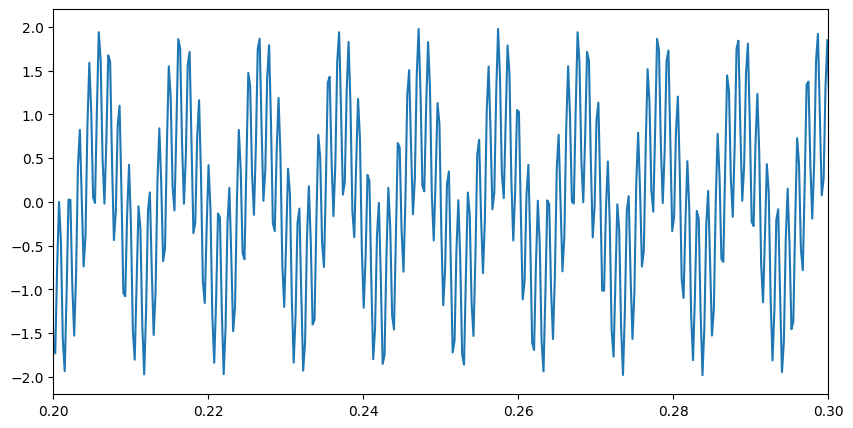

In [2]:
NUM_POINTS = 2**12

t = np.linspace(0, 1, NUM_POINTS)

# change below to change the specific form. this is the same as the textbook - 2 tone signal
x = np.cos(2*97*np.pi*t) + np.cos(2*777*np.pi*t)

plt.figure(figsize=(10,5))
plt.plot(t, x)
plt.xlim(0.2, 0.3)
plt.show()

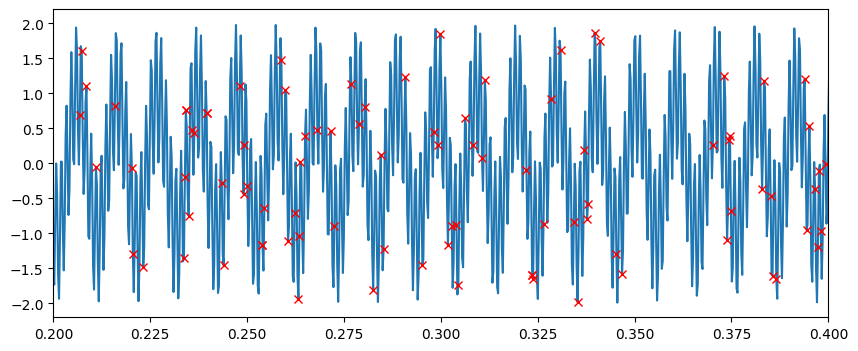

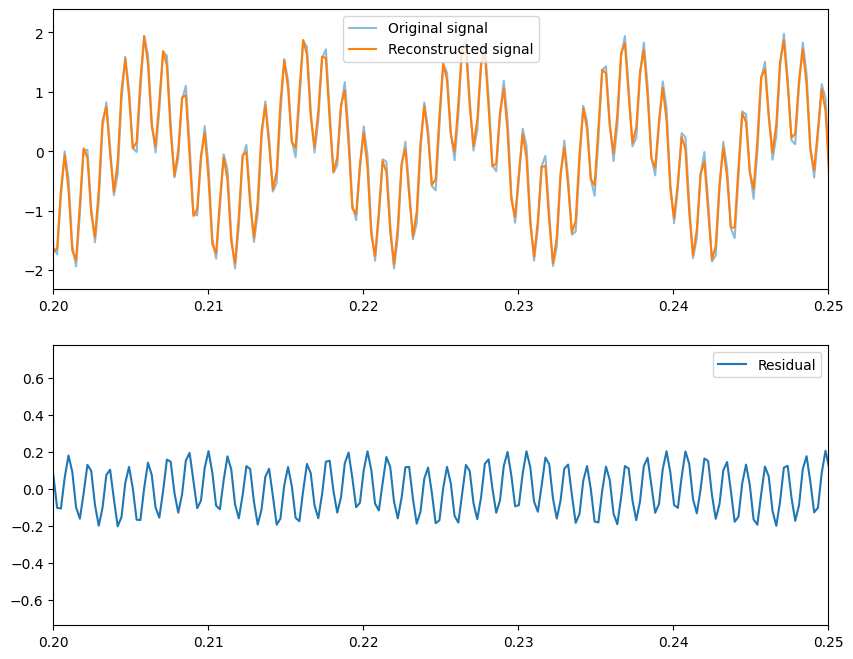

In [25]:
xt = np.fft.fft(x)
# Power spectral density
PSD = xt * np.conjugate(xt) / NUM_POINTS

# take a random sample in line with sample_count
sample_count = 500
sample_count = int(sample_count) # ensure no float

selections = np.round(np.random.rand(sample_count, 1) * NUM_POINTS)
selections = [int(e[0]) for e in selections]

y = x[selections]
plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.plot(t[selections], y, 'x', color='red')
plt.xlim(0.2, 0.4)
plt.show()

# create generic Psi
# make a NxN identity matrix
identity = np.eye(NUM_POINTS, NUM_POINTS)
# implement discrete cosign transform on identity matrix (from scipy.fftpack)
psi = dct(identity)
# take theta, our p * n matrix featuring what measurements are made 
# selections is a vector representing where samples have been made
theta = psi[selections, :]

# apply cosamp algorithm
s = cosamp(theta, y, 4)

x_r = idct(s)
lim = (0.2, 0.25)
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(t, x, alpha=0.5, label='Original signal')
plt.plot(t, x_r, label='Reconstructed signal')
plt.legend()
plt.xlim(*lim)
plt.subplot(2, 1, 2)
plt.plot(t, x-x_r, label='Residual')
plt.legend()
plt.xlim(*lim)
plt.show()


## 2 - formalising 

In [ ]:
def 